本 notebook 是 [M03.2 数据处理](../notes/02-data-wrangling.qmd) 的实例讲解。

1. 1. tidy data、索引与关联基数
2. 2. 缺失机制与完整案例偏差
3. 3. 训练数据拟合预处理，统一变换接口
4. 4. 向量化、组内变换与异常值敏感性

在 VS Code 中选择仓库 `.venv` 内核，逐单元运行；运行结果随文件保存。示例使用固定随机种子和合成数据。

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib_inline.backend_inline import set_matplotlib_formats
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler, StandardScaler

from semiai.plotting import BLUE, GRAY, use_style

use_style()
set_matplotlib_formats("svg")
rng = np.random.default_rng(42)

## 1. tidy data、索引与关联基数

一行代表一次观测，一列代表一个变量；用 melt/pivot 检查往返，再故意制造重复键，让关联验证提前失败。

In [2]:
wide = pd.DataFrame({"sample": ["A", "B"], "energy_300": [-2.0, -1.0], "energy_600": [-1.8, -0.8]})
long = wide.melt(id_vars="sample", var_name="measurement", value_name="energy")
restored = long.pivot(index="sample", columns="measurement", values="energy").reset_index()
print(long)
assert np.allclose(restored[["energy_300", "energy_600"]], wide[["energy_300", "energy_600"]])
meta = pd.DataFrame({"sample": ["A", "A", "B"], "batch": [1, 2, 3]})
try:
    wide.merge(meta, on="sample", validate="one_to_one")
except pd.errors.MergeError as error:
    print("关联基数检查:", type(error).__name__)
a = pd.Series([1.0, 2.0], index=["A", "B"])
b = pd.Series([10.0, 20.0], index=["B", "A"])
print("标签对齐:", (a + b).to_dict(), "仅按位置:", a.to_numpy() + b.to_numpy())

  sample measurement  energy
0      A  energy_300    -2.0
1      B  energy_300    -1.0
2      A  energy_600    -1.8
3      B  energy_600    -0.8
关联基数检查: MergeError
标签对齐: {'A': 21.0, 'B': 12.0} 仅按位置: [11. 22.]


读法：重塑保留了观测键；索引对齐按标签而非位置。重复键应先判断是否属于合法重复观测，不应直接 drop_duplicates 掩盖多对多关系。

## 2. 缺失机制与完整案例偏差

在知道完整合成数据的条件下，检查依赖测量值的缺失如何改变观测分布，并与独立随机缺失比较。

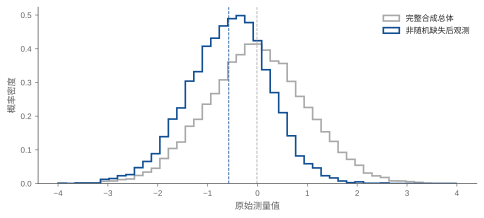

                     sample      mean  count
0                      full -0.010397  14000
1             MCAR observed -0.005909   9172
2  value-dependent observed -0.575434   7097
可空整数类型: Int64 缺失掩码: [False, True, False]


In [3]:
raw = rng.normal(size=14000)
missing = rng.random(len(raw)) < 1 / (1 + np.exp(-1.8 * raw))
observed = raw[~missing]
fig, ax = plt.subplots(figsize=(6.8, 3.1))
bins = np.linspace(-4, 4, 48)
ax.hist(raw, bins=bins, density=True, histtype="step", color=GRAY, lw=1.6, label="完整合成总体")
ax.hist(
    observed, bins=bins, density=True, histtype="step", color=BLUE, lw=1.6, label="非随机缺失后观测"
)
ax.axvline(raw.mean(), color=GRAY, ls="--", lw=0.8)
ax.axvline(observed.mean(), color=BLUE, ls="--", lw=0.8)
ax.set(xlabel="原始测量值", ylabel="概率密度")
ax.legend()
fig.tight_layout()
plt.show()

mcar = rng.random(len(raw)) < 0.35
print(
    pd.DataFrame(
        {
            "sample": ["full", "MCAR observed", "value-dependent observed"],
            "mean": [raw.mean(), raw[~mcar].mean(), observed.mean()],
            "count": [len(raw), (~mcar).sum(), len(observed)],
        }
    )
)
nullable = pd.Series([1, None, 3], dtype="Int64")
print("可空整数类型:", nullable.dtype, "缺失掩码:", nullable.isna().tolist())

读法：依赖未观测值的缺失会改变可见总体；均值填补不能仅凭观测数据恢复丢失部分。MCAR/MAR/MNAR 是数据生成假设，不是由一个缺失率数字就能判定的标签。

## 3. 训练数据拟合预处理，统一变换接口

把连续变量的填补和缩放、类别变量的编码放进 ColumnTransformer，检查测试数据没有重新拟合尺度。

In [4]:
train = pd.DataFrame({"sensor": [1.0, 2.0, np.nan, 4.0], "batch": ["A", "A", "B", "B"]})
test = pd.DataFrame({"sensor": [100.0, np.nan], "batch": ["C", "A"]})
pre = ColumnTransformer(
    [
        ("numeric", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), ["sensor"]),
        ("category", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["batch"]),
    ]
)
train_z = pre.fit_transform(train)
test_z = pre.transform(test)
print("特征名称:", pre.get_feature_names_out())
print("训练变换:", train_z, "\n测试变换:", test_z)
scaler = pre.named_transformers_["numeric"].named_steps["standardscaler"]
print("仅来自训练数据的均值:", scaler.mean_)
assert np.allclose(scaler.mean_, [2.25])

特征名称: ['numeric__sensor' 'category__batch_A' 'category__batch_B']
训练变换: [[-1.14707867  1.          0.        ]
 [-0.22941573  1.          0.        ]
 [-0.22941573  0.          1.        ]
 [ 1.60591014  0.          1.        ]] 
测试变换: [[89.70155194  0.          0.        ]
 [-0.22941573  1.          0.        ]]
仅来自训练数据的均值: [2.25]


读法：测试中的极值没有改变训练尺度；未知类别被编码为该类别块的全零，需要明确它与缺失类别或基准类别的区别。

## 4. 向量化、组内变换与异常值敏感性

同一个组内中心化先用 transform 表达，再比较标准缩放与稳健缩放面对极端值的行为。

In [5]:
table = pd.DataFrame({"run": np.repeat(["A", "B"], 5), "signal": np.arange(10, dtype=float)})
table["centered"] = table.signal - table.groupby("run").signal.transform("mean")
print(table)
print("各组中心化和:", table.groupby("run").centered.sum().to_dict())
base = rng.normal(size=1000)
contaminated = np.r_[base, 100.0].reshape(-1, 1)
for scaler in (StandardScaler(), RobustScaler()):
    scaler.fit(contaminated)
    print(
        type(scaler).__name__, "正常区间 [-1,1] 的变换:", scaler.transform([[-1.0], [1.0]]).ravel()
    )
assert np.allclose(table.groupby("run").centered.sum(), 0)

  run  signal  centered
0   A     0.0      -2.0
1   A     1.0      -1.0
2   A     2.0       0.0
3   A     3.0       1.0
4   A     4.0       2.0
5   B     5.0      -2.0
6   B     6.0      -1.0
7   B     7.0       0.0
8   B     8.0       1.0
9   B     9.0       2.0
各组中心化和: {'A': 0.0, 'B': 0.0}
StandardScaler 正常区间 [-1,1] 的变换: [-0.30694044  0.29717931]
RobustScaler 正常区间 [-1,1] 的变换: [-0.68422322  0.84060016]


读法：transform 保留逐行粒度并按索引对齐；标准缩放对均值和方差敏感，稳健缩放使用中位数和四分位距。异常是否删除仍需要来源与机制判断。

## 小结

先定义观测粒度和 schema，再做关联与重塑；先解释缺失和异常的来源，再选择填补或删除。缩放与编码决定模型看到的几何，拟合状态必须保存并一致复用，pandas 的标签机制则必须被显式理解。